<h2>Modelling: Future Price Direction 4 (LSTM)

<h3>Data Preparation

In [1]:
# Load pre split data:
from project_paths import RAW_DATA_PATH
import pandas as pd

from bta_direction_functions import add_direction
print(RAW_DATA_PATH)

raw_data = pd.read_pickle(RAW_DATA_PATH)
nd_data = raw_data.copy()
nd_data.head()

/Users/cameroncochrane/Data Projects/vlXsnPPgKKnWqEJB/experimentation/data/raw/btcusd_data.pkl


Price,Date,Close,High,Low,Open,Volume
0,2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800
1,2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200
2,2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700
3,2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600
4,2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100


In [2]:
data_20 = add_direction(data=nd_data, shift=20, price="Close")
data_20 = data_20.drop(columns=["Date"])
data_20.head()

Price,Close,High,Low,Open,Volume,Direction_20
0,457.334015,468.174011,452.421997,465.864014,21056800,0
1,424.440002,456.859985,413.104004,456.859985,34483200,0
2,394.795990,427.834991,384.532013,424.102997,37919700,0
3,408.903992,423.295990,389.882996,394.673004,36863600,0
4,398.821014,412.425995,393.181000,408.084991,26580100,0


In [3]:
from bta_direction_functions import add_EMA, add_SMA

Let's add _5 (1 week), _10 (2 week_), _20 (1 month) SMAs and EMAs. Leave out MACD, RSI and ATR.

In [4]:
data_20 = add_SMA(data=data_20,n=5,price="Close")
data_20 = add_SMA(data=data_20,n=10,price="Close")
data_20 = add_SMA(data=data_20,n=20,price="Close")

data_20 = add_EMA(data=data_20,n=5,price="Close")
data_20 = add_EMA(data=data_20,n=10,price="Close")
data_20 = add_EMA(data=data_20,n=20,price="Close")

In [5]:
data_20 = data_20.dropna().copy() # Drop NA rows
data_20.head()

Price,Close,High,Low,Open,Volume,Direction_20,SMA_5,SMA_10,SMA_20,EMA_5,EMA_10,EMA_20
19,330.079010,345.134003,302.559998,320.389008,79011800,1,342.807800,363.676599,389.910399,341.195946,359.626329,383.883180
20,336.187012,339.247009,320.481995,330.584015,49199900,1,335.030804,357.343301,383.853049,339.526301,355.364635,379.340688
21,352.940002,354.364014,327.187988,336.115997,54736300,1,333.716406,354.919202,380.278049,343.997535,354.923793,376.826337
22,365.026001,382.726013,347.687012,352.747986,83641104,0,340.948407,353.875101,378.789549,351.007024,356.760558,375.702495
23,361.562012,375.066986,352.963013,364.687012,43665700,0,349.158807,351.336902,376.422450,354.525353,357.633549,374.355783


In [6]:
from plotly.subplots import make_subplots
from typing import List

import plotly.graph_objects as go


def plot_candlestick(data: pd.DataFrame, ma_prefixes: List[str] = ["SMA_", "EMA_"], title: str = "BTC-USD Price") -> go.Figure:
    """
    Plot an OHLC candlestick chart with moving averages and volume bars.

    Args:
        data: DataFrame with Open, High, Low, Close, Volume columns and SMA_/EMA_ columns.
        ma_prefixes: Column name prefixes identifying moving average columns to overlay.
        title: Chart title.

    Returns:
        Plotly Figure (legend acts as the key).

    Example:
        fig = plot_candlestick(data_20.drop(columns=["Direction_20"]))
        fig.show()
    """
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.03, row_heights=[0.75, 0.25])
    fig.add_trace(go.Candlestick(x=data.index, open=data["Open"], high=data["High"], low=data["Low"], close=data["Close"], name="Price"), row=1, col=1)
    for col in [c for c in data.columns if c.startswith(tuple(ma_prefixes))]:
        fig.add_trace(go.Scatter(x=data.index, y=data[col], mode="lines", name=col, line=dict(width=1, dash="dot" if col.startswith("EMA") else "solid")), row=1, col=1)
    fig.add_trace(go.Bar(x=data.index, y=data["Volume"], name="Volume", marker_color="grey"), row=2, col=1)
    fig.update_layout(title=title, height=800, xaxis_rangeslider_visible=False, legend_title_text="Key", hovermode="x unified")
    fig.update_yaxes(title_text="Price (USD)", row=1, col=1)
    fig.update_yaxes(title_text="Volume", row=2, col=1)
    return fig


# Use the Date column from nd_data as the x-axis (data_20 had Date dropped; indices align with nd_data)
plot_data = data_20.drop(columns=["Direction_20"]).copy()
plot_data.index = pd.to_datetime(nd_data.loc[plot_data.index, "Date"])
plot_candlestick(plot_data).show()

- Remove Volume, Open, SMA_5, and Low in the modelling pipeline based on the feature selection from the previous notebook.
- Temporal train-test split.
- Scale numerical features on training split
- Add overlap sequences
- Train an LSTM.

In [7]:
X = data_20.drop(columns=["Direction_20"])
y = data_20["Direction_20"]

In [8]:
split_idx = int(len(X) * 0.8)
val_idx = int(split_idx * 0.8)

X_train, X_val, X_test = X.iloc[:val_idx], X.iloc[val_idx:split_idx], X.iloc[split_idx:]
y_train, y_val, y_test = y.iloc[:val_idx], y.iloc[val_idx:split_idx], y.iloc[split_idx:]

print(f"Training samples: {len(X_train)} | Validation samples: {len(X_val)} | Test samples: {len(X_test)}")

Training samples: 2790 | Validation samples: 698 | Test samples: 872


<h4>Data Preprocessing Pipeline:

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

In [10]:
# Function to generate lag features in a pipeline:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class RollingWindowTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, lookback=96):
        self.lookback = lookback

    def fit(self, X, y=None):
        X = np.asarray(X)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self)

        X = np.asarray(X, dtype=np.float32)

        if X.ndim != 2:
            raise ValueError("X must be 2D")

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Number of features has changed")

        if not 1 <= self.lookback <= len(X):
            raise ValueError("Invalid lookback")

        return np.stack([
            X[i:i + self.lookback]
            for i in range(len(X) - self.lookback + 1)
        ])

In [11]:
lookback = 48

In [12]:
# Processing pipeleine only not a modelling pipeline:
process_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rolling", RollingWindowTransformer(lookback=lookback))
])

In [13]:
X_train_seq = process_pipeline.fit_transform(X_train)
X_val_seq = process_pipeline.transform(X_val)
X_test_seq = process_pipeline.transform(X_test)

print(X_train_seq.shape)
print(X_val_seq.shape)
print(X_test_seq.shape)

(2743, 48, 11)
(651, 48, 11)
(825, 48, 11)


In [14]:
# The rolling transformation reduces the number of samples by lookback - 1. Consequently, the target must be aligned with the end of each sequence:

y_train_seq = np.asarray(y_train)[lookback - 1:]
y_val_seq = np.asarray(y_val)[lookback - 1:]
y_test_seq = np.asarray(y_test)[lookback - 1:]

print(y_train_seq.shape)
print(y_val_seq.shape)
print(y_test_seq.shape)

(2743,)
(651,)
(825,)


In [15]:
# Check that the pipeline is fitted. If this runs without an error, the pipeline is recognised as fitted:
check_is_fitted(process_pipeline)

print(process_pipeline.named_steps["rolling"].n_features_in_)

11


<h3>LSTM Model Training

In [16]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

<h4>Model Definition:

In [17]:
tf.keras.utils.set_random_seed(13)

model_1 = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),

    LSTM(
        units=32,
        return_sequences=False
    ),

    Dropout(0.2),

    Dense(
        units=16,
        activation="relu",
        kernel_regularizer=l2(1e-4)
    ),

    Dense(
        units=1,
        activation="sigmoid"
    )
])

model_1.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

model_1.summary()

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=20,
        min_delta=1e-4,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=20,
        min_lr=1e-5
    )
]

history_1 = model_1.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=1000,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks, 
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,177 (24.13 KB)

 Trainable params: 6,177 (24.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5534 - loss: 0.6908 - roc_auc: 0.5310 - val_accuracy: 0.4839 - val_loss: 0.6967 - val_roc_auc: 0.5453 - learning_rate: 0.0010
Epoch 2/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5713 - loss: 0.6836 - roc_auc: 0.5648 - val_accuracy: 0.5100 - val_loss: 0.6933 - val_roc_auc: 0.5574 - learning_rate: 0.0010
Epoch 3/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5906 - loss: 0.6732 - roc_auc: 0.5860 - val_accuracy: 0.4992 - val_loss: 0.6949 - val_roc_auc: 0.5162 - learning_rate: 0.0010
Epoch 4/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5917 - loss: 0.6733 - roc_auc: 0.5872 - val_accuracy: 0.4992 - val_loss: 0.6974 - val_roc_auc: 0.5111 - learning_rate: 0.0010
Epoch 5/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5884 - loss: 0.6760 - roc_auc: 0.5815 - val_accuracy: 0.5131 - val_loss: 0.6949 - val_roc_auc: 0.4996 - learning_rate: 0.0010
Epoch 6/1000
43/43 ━━━━━━━━━━━━━━━━━━━━

In [18]:
best_epoch_idx = int(np.argmin(history_1.history["val_loss"])) # Define best epoch as the one with the lowest validation loss.

print(f"Best epoch: {best_epoch_idx + 1}")
for metric, values in history_1.history.items():
    print(f"{metric}: {values[best_epoch_idx]:.4f}")

Best epoch: 9
accuracy: 0.5993
loss: 0.6668
roc_auc: 0.5984
val_accuracy: 0.5269
val_loss: 0.6911
val_roc_auc: 0.4737
learning_rate: 0.0010


That was a fairly simple model that may not have been able to pick up any complex temporal relationships that may be present becuase it is only a single layer model. We have however established a baseline model (and modelling layout) making subsquent experimentation easier.

In [19]:
model_2 = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),

    # First LSTM layer
    LSTM(
        units=128,
        return_sequences=True
    ),
    Dropout(0.5),

    # Second LSTM layer
    LSTM(
        units=64,
        return_sequences=True
    ),
    Dropout(0.5),

    # Third LSTM layer
    LSTM(
        units=32,
        return_sequences=False
    ),
    Dropout(0.5),

    # Fully connected layers
    Dense(
        units=32,
        activation="relu",
        kernel_regularizer=l2(1e-4)
    ),
    Dropout(0.5),

    Dense(
        units=16,
        activation="relu",
        kernel_regularizer=l2(1e-4)
    ),

    # Binary classification output
    Dense(
        units=1,
        activation="sigmoid"
    )
])

model_2.compile(
    optimizer=Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 48, 128)        │        71,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 48, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 48, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 135,105 (527.75 KB)

 Trainable params: 135,105 (527.75 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=20,
        min_delta=1e-4,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=20,
        min_lr=1e-6
    )
]

history_2 = model_2.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=1000,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks, 
    verbose=1
)

Epoch 1/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.5611 - loss: 0.6954 - roc_auc: 0.4973 - val_accuracy: 0.5407 - val_loss: 0.6980 - val_roc_auc: 0.4688 - learning_rate: 3.0000e-04
Epoch 2/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.5756 - loss: 0.6872 - roc_auc: 0.5476 - val_accuracy: 0.4823 - val_loss: 0.6993 - val_roc_auc: 0.4985 - learning_rate: 3.0000e-04
Epoch 3/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.5775 - loss: 0.6839 - roc_auc: 0.5631 - val_accuracy: 0.4916 - val_loss: 0.7011 - val_roc_auc: 0.4729 - learning_rate: 3.0000e-04
Epoch 4/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.5786 - loss: 0.6863 - roc_auc: 0.5577 - val_accuracy: 0.4839 - val_loss: 0.7032 - val_roc_auc: 0.4681 - learning_rate: 3.0000e-04
Epoch 5/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.5804 - loss: 0.6846 - roc_auc: 0.5669 - val_accuracy: 0.4608 - val_loss: 0.7040 - val_roc_auc: 0.4641 - learning_rate: 3.0000e-04
Epoch 6/1000
43

The problem with higher parameter models on relatively small training datasets like we have here is the risk of overfitting.

- Are we going about this properly? Are we naive to just assume that the lookback periods we have been selecting are good enough.

    - Read the following article: https://medium.com/data-science-collective/future-forecasting-of-time-series-using-lstm-a-quick-guide-for-business-leaders-370661c574c9

    - In this article the author uses partial auto correlation function (PACF) which measures how much the y variable is correlated to past values of itself and how far back a statistically significant correlation exists. The scalecast library is also used. scalecast is an ML library for time-series modelling that simplifies the whole process. May be worth trying?

- Is it worth simplifying by removing all features except 'Close'. The model may be overcomplicated with all these different features.

In [21]:
simple_data = data_20[["Close", "Direction_20"]]
simple_data.head()

Price,Close,Direction_20
19,330.079010,1
20,336.187012,1
21,352.940002,1
22,365.026001,0
23,361.562012,0


In [22]:
X = simple_data[["Close"]] #Use double brackes to make sure a pd.Dataframe (not pd.Series) is created. Pipeline messes up otherwise?
y = simple_data["Direction_20"]

split_idx = int(len(X) * 0.8)
val_idx = int(split_idx * 0.8)

X_train, X_val, X_test = X.iloc[:val_idx], X.iloc[val_idx:split_idx], X.iloc[split_idx:]
y_train, y_val, y_test = y.iloc[:val_idx], y.iloc[val_idx:split_idx], y.iloc[split_idx:]

print(f"Training samples: {len(X_train)} | Validation samples: {len(X_val)} | Test samples: {len(X_test)}")
print(type(X_train), X_train.shape, X_val.shape, X_test.shape)

Training samples: 2790 | Validation samples: 698 | Test samples: 872
<class 'pandas.DataFrame'> (2790, 1) (698, 1) (872, 1)


In [ ]:
process_pipeline = Pipeline([
    ("columns", ColumnTransformer(
    [("close", "passthrough", ["Close"])], remainder="drop")),
    ("scaler", StandardScaler()),
    ("rolling", RollingWindowTransformer(lookback=lookback))
])

In [24]:
X_train_seq = process_pipeline.fit_transform(X_train)
X_val_seq = process_pipeline.transform(X_val)
X_test_seq = process_pipeline.transform(X_test)

print(X_train_seq.shape)
print(X_val_seq.shape)
print(X_test_seq.shape)

y_train_seq = np.asarray(y_train)[lookback - 1:]
y_val_seq = np.asarray(y_val)[lookback - 1:]
y_test_seq = np.asarray(y_test)[lookback - 1:]

print(y_train_seq.shape)
print(y_val_seq.shape)
print(y_test_seq.shape)

check_is_fitted(process_pipeline)

print(process_pipeline.named_steps["rolling"].n_features_in_)

(2743, 48, 1)
(651, 48, 1)
(825, 48, 1)
(2743,)
(651,)
(825,)
1


In [25]:
tf.keras.utils.set_random_seed(13)

model_simple = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),

    LSTM(
        units=32,
        return_sequences=False
    ),

    Dropout(0.2),

    Dense(
        units=16,
        activation="relu",
        kernel_regularizer=l2(1e-4)
    ),

    Dense(
        units=1,
        activation="sigmoid"
    )
])

model_simple.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

model_simple.summary()

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=20,
        min_delta=1e-4,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=20,
        min_lr=1e-5
    )
]

history_simple = model_simple.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=1000,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks, 
    verbose=1
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5680 - loss: 0.6862 - roc_auc: 0.5338 - val_accuracy: 0.5668 - val_loss: 0.6932 - val_roc_auc: 0.4551 - learning_rate: 0.0010
Epoch 2/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5746 - loss: 0.6769 - roc_auc: 0.5768 - val_accuracy: 0.4255 - val_loss: 0.7012 - val_roc_auc: 0.5129 - learning_rate: 0.0010
Epoch 3/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5727 - loss: 0.6783 - roc_auc: 0.5724 - val_accuracy: 0.4654 - val_loss: 0.6992 - val_roc_auc: 0.5310 - learning_rate: 0.0010
Epoch 4/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5818 - loss: 0.6748 - roc_auc: 0.5812 - val_accuracy: 0.4793 - val_loss: 0.6984 - val_roc_auc: 0.5245 - learning_rate: 0.0010
Epoch 5/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5800 - loss: 0.6758 - roc_auc: 0.5736 - val_accuracy: 0.4823 - val_loss: 0.6968 - val_roc_auc: 0.5486 - learning_rate: 0.0010
Epoch 6/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 

In [26]:
model_simple_2 = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),

    # First LSTM layer
    LSTM(
        units=128,
        return_sequences=True
    ),
    Dropout(0.2),

    # Second LSTM layer
    LSTM(
        units=64,
        return_sequences=True
    ),
    Dropout(0.2),

    # Third LSTM layer
    LSTM(
        units=32,
        return_sequences=False
    ),
    Dropout(0.2),

    # Fully connected layers
    Dense(
        units=32,
        activation="relu",
        kernel_regularizer=l2(1e-4)
    ),
    Dropout(0.2),

    Dense(
        units=16,
        activation="relu",
        kernel_regularizer=l2(1e-4)
    ),

    # Binary classification output
    Dense(
        units=1,
        activation="sigmoid"
    )
])

model_simple_2.compile(
    optimizer=Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

model_simple_2.summary()

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=20,
        min_delta=1e-4,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=20,
        min_lr=1e-5
    )
]

history_simple_2 = model_simple_2.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=1000,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks, 
    verbose=1
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_5 (LSTM)                   │ (None, 48, 128)        │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 48, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 48, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,985 (507.75 KB)

 Trainable params: 129,985 (507.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.5538 - loss: 0.6936 - roc_auc: 0.5276 - val_accuracy: 0.4332 - val_loss: 0.6993 - val_roc_auc: 0.5099 - learning_rate: 3.0000e-04
Epoch 2/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.5855 - loss: 0.6828 - roc_auc: 0.5638 - val_accuracy: 0.4255 - val_loss: 0.7046 - val_roc_auc: 0.5156 - learning_rate: 3.0000e-04
Epoch 3/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.5771 - loss: 0.6842 - roc_auc: 0.5623 - val_accuracy: 0.4255 - val_loss: 0.7050 - val_roc_auc: 0.5150 - learning_rate: 3.0000e-04
Epoch 4/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.5797 - loss: 0.6825 - roc_auc: 0.5640 - val_accuracy: 0.4255 - val_loss: 0.7032 - val_roc_auc: 0.5315 - learning_rate: 3.0000e-04
Epoch 5/1000
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.5818 - loss: 0.6815 - roc_auc: 0.5696 - val_accuracy: 0.4654 - val_loss: 0.7035 - val_roc_auc: 0.5226 - learning_rate: 3.0000e-04
Epoch 6/1000
43

For now take one of the models, save it (and the preprocessing pipeline), then use it in the stack. Get the app working first then optimize the models.

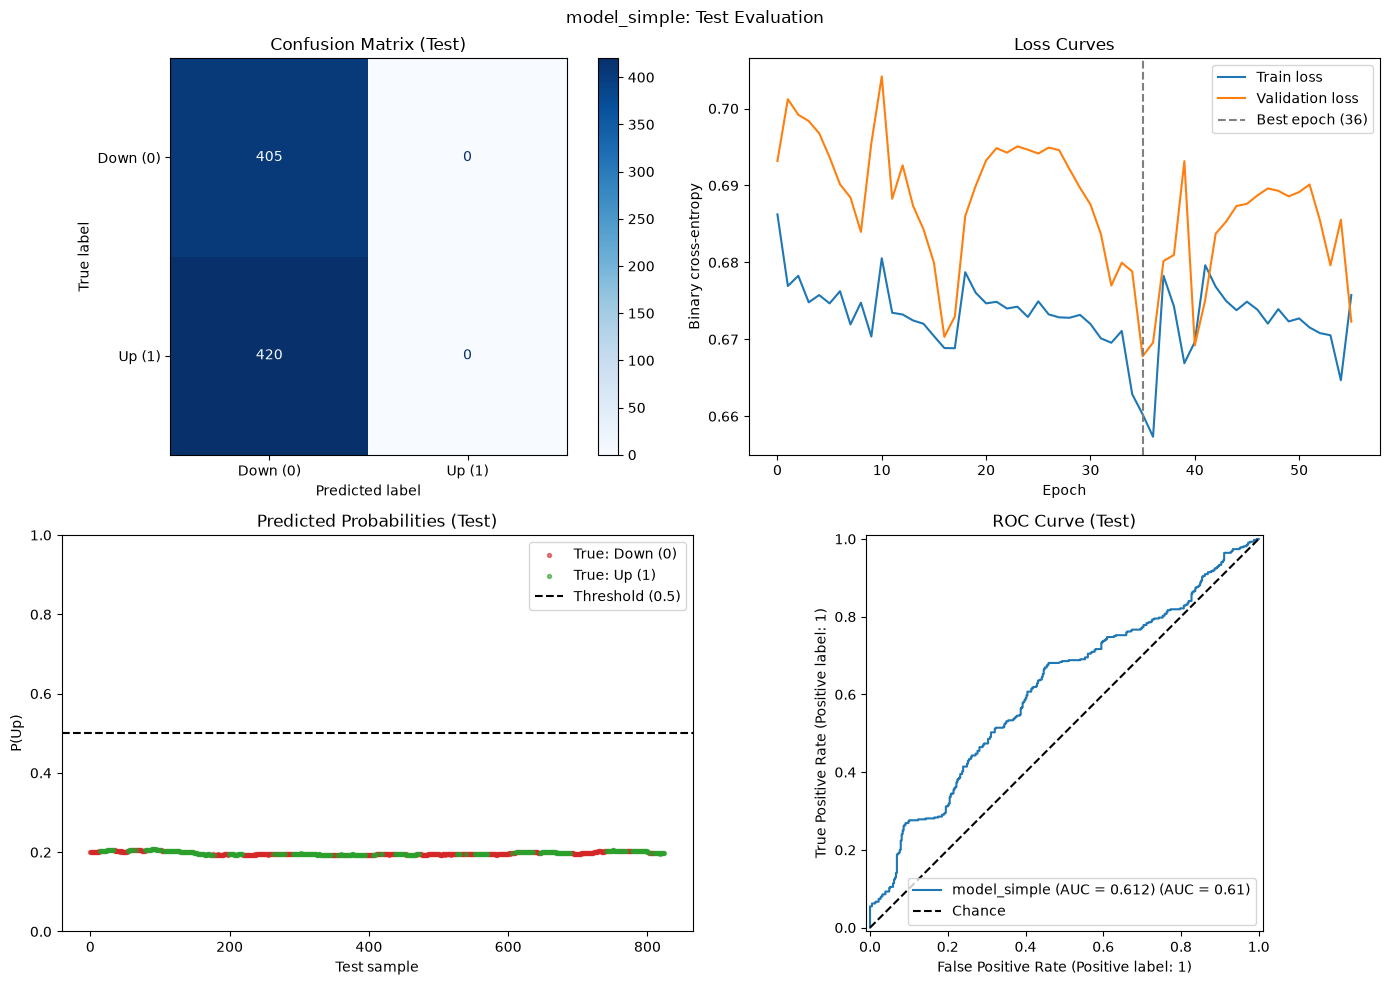

              precision    recall  f1-score   support

    Down (0)       0.49      1.00      0.66       405
      Up (1)       0.00      0.00      0.00       420

    accuracy                           0.49       825
   macro avg       0.25      0.50      0.33       825
weighted avg       0.24      0.49      0.32       825

model_simple {'accuracy': 0.4909090909090909, 'roc_auc': 0.6119135802469136, 'best_epoch': 36}


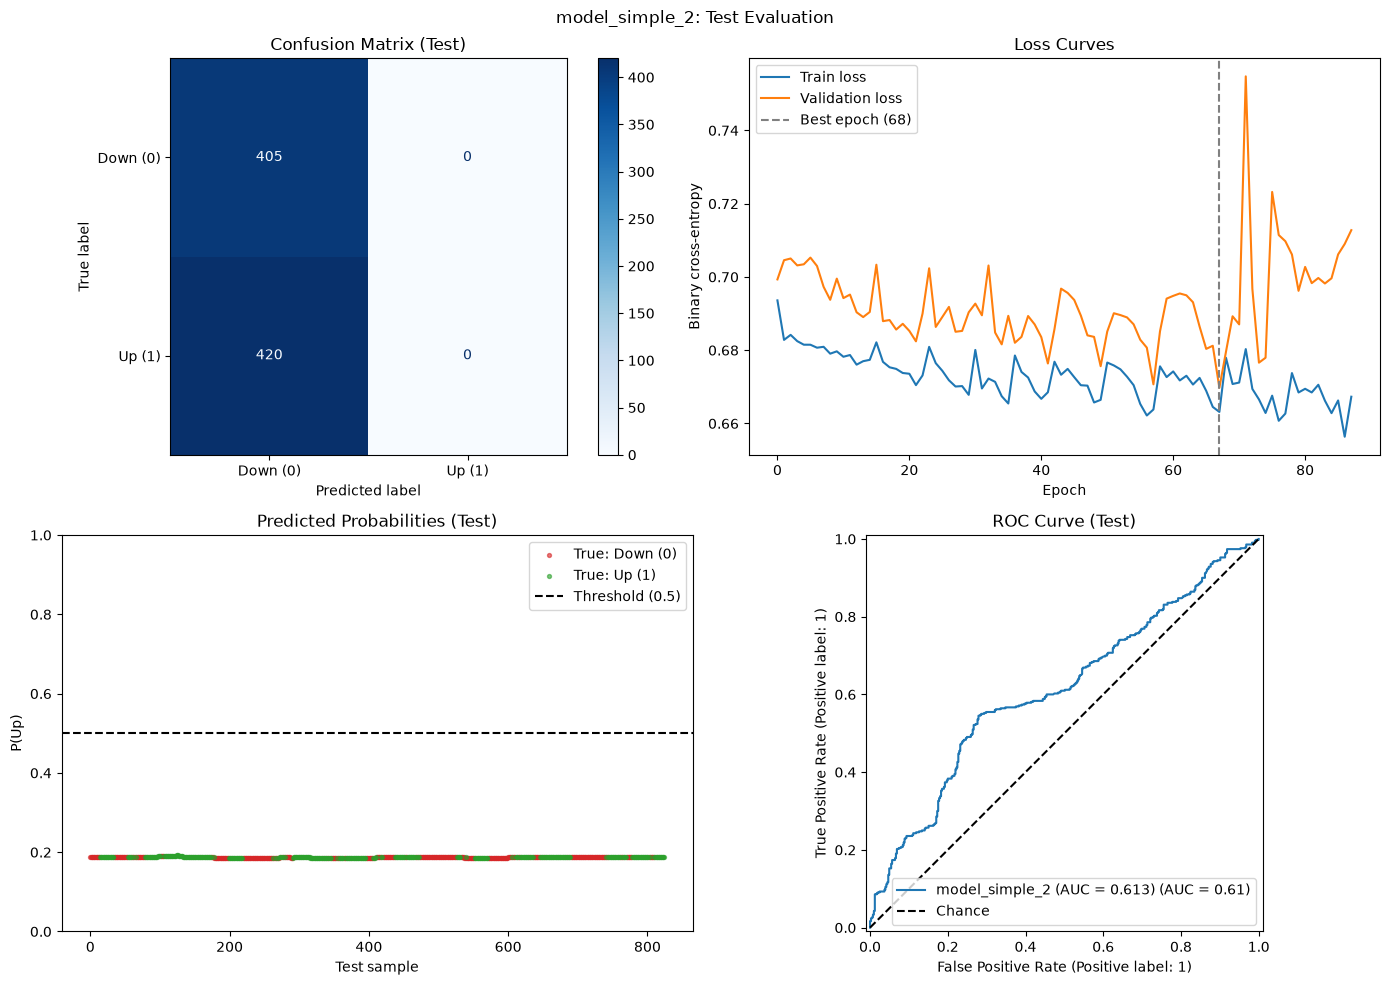

              precision    recall  f1-score   support

    Down (0)       0.49      1.00      0.66       405
      Up (1)       0.00      0.00      0.00       420

    accuracy                           0.49       825
   macro avg       0.25      0.50      0.33       825
weighted avg       0.24      0.49      0.32       825

model_simple_2 {'accuracy': 0.4909090909090909, 'roc_auc': 0.612989417989418, 'best_epoch': 68}


In [27]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report, roc_auc_score

import matplotlib.pyplot as plt


def evaluate_binary_classifier(model: tf.keras.Model, history: tf.keras.callbacks.History, X_test_seq: np.ndarray, y_test_seq: np.ndarray, name: str = "Model", threshold: float = 0.5) -> dict:
    """
    Evaluate a trained Keras binary classifier on test data.

    Plots a confusion matrix, loss curves, predicted probabilities (coloured by true class) and a ROC curve.

    Args:
        model: Trained Keras model with a sigmoid output.
        history: History object returned by model.fit (needs 'loss' and 'val_loss').
        X_test_seq: Test input sequences, shape (samples, lookback, features).
        y_test_seq: Binary test labels aligned to the sequences.
        name: Label used in plot titles.
        threshold: Probability cut-off for predicting class 1.

    Returns:
        Dict with test accuracy, ROC AUC and the best epoch (lowest val_loss).

    Example:
        evaluate_binary_classifier(model_simple, history_simple, X_test_seq, y_test_seq, name="Simple LSTM")
    """
    y_true = np.asarray(y_test_seq).astype(int)
    y_prob = model.predict(X_test_seq, verbose=0).ravel()
    y_pred = (y_prob >= threshold).astype(int)
    auc = float(roc_auc_score(y_true, y_prob))

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f"{name}: Test Evaluation")

    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=["Down (0)", "Up (1)"], cmap="Blues", ax=axes[0, 0])
    axes[0, 0].set_title("Confusion Matrix (Test)")

    best_epoch = int(np.argmin(history.history["val_loss"]))
    axes[0, 1].plot(history.history["loss"], label="Train loss")
    axes[0, 1].plot(history.history["val_loss"], label="Validation loss")
    axes[0, 1].axvline(best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch + 1})")
    axes[0, 1].set(title="Loss Curves", xlabel="Epoch", ylabel="Binary cross-entropy")
    axes[0, 1].legend()

    for cls, colour, label in [(0, "tab:red", "Down (0)"), (1, "tab:green", "Up (1)")]:
        mask = y_true == cls
        axes[1, 0].scatter(np.flatnonzero(mask), y_prob[mask], s=8, c=colour, alpha=0.6, label=f"True: {label}")
    axes[1, 0].axhline(threshold, color="black", linestyle="--", label=f"Threshold ({threshold})")
    axes[1, 0].set(title="Predicted Probabilities (Test)", xlabel="Test sample", ylabel="P(Up)", ylim=(0, 1))
    axes[1, 0].legend()

    RocCurveDisplay.from_predictions(y_true, y_prob, name=f"{name} (AUC = {auc:.3f})", ax=axes[1, 1])
    axes[1, 1].plot([0, 1], [0, 1], "k--", label="Chance")
    axes[1, 1].set_title("ROC Curve (Test)")
    axes[1, 1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()

    print(classification_report(y_true, y_pred, target_names=["Down (0)", "Up (1)"], zero_division=0))
    return {"accuracy": float((y_pred == y_true).mean()), "roc_auc": auc, "best_epoch": best_epoch + 1}


# Models trained on the single-feature (Close) data matching the current X_test_seq:
for m, h, n in [(model_simple, history_simple, "model_simple"), (model_simple_2, history_simple_2, "model_simple_2")]:
    print(n, evaluate_binary_classifier(m, h, X_test_seq, y_test_seq, name=n))

'model_simple' seems to be the best model...

In [28]:
from pathlib import Path
import joblib

artifact_dir = Path("models")
artifact_dir.mkdir(parents=True, exist_ok=True)

# Only load this joblib file from a trusted source.
joblib.dump(process_pipeline, artifact_dir / "process_pipeline.joblib")
model_simple.save(artifact_dir / "model_simple.keras")